# 06 - Results, Ablations, Final Holdout Evaluation

Two things: the ablations promised since notebook 00 (Kalman vs rolling-OLS hedge ratio, HMM filter on/off, cost sensitivity), and then, once only, the holdout evaluation - running the frozen pipeline on 2024-08-15 onward, data nothing has touched until now.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from hmmlearn.hmm import GaussianHMM

warnings.filterwarnings("ignore", message="Model is not converging")

DATA_DIR = "../data"

with open(f"{DATA_DIR}/config.json") as f: config = json.load(f)
with open(f"{DATA_DIR}/pair_selection_decisions.json") as f: decisions = json.load(f)
with open(f"{DATA_DIR}/kalman_config.json") as f: kconfig = json.load(f)
with open(f"{DATA_DIR}/regime_config.json") as f: rconfig = json.load(f)
with open(f"{DATA_DIR}/signal_config.json") as f: sconfig = json.load(f)
with open(f"{DATA_DIR}/backtest_config.json") as f: bconfig = json.load(f)

HOLDOUT_START = config["holdout_start"]

fx_sig = pd.read_parquet(f"{DATA_DIR}/signals_fx.parquet")
comm_sig = pd.read_parquet(f"{DATA_DIR}/signals_comm.parquet")

# rebuild from the pre-z-score-trim source rather than reusing signals_fx/comm_sig - those were
# already trimmed by notebook 04's own rolling z-score, so recomputing z on them again would need
# ~z_window more days of history than they have left, quietly shifting the start date and breaking
# the "reproduces notebook 05 exactly" check below
def prep(df, regime):
    return df.join(regime, how="inner").dropna(subset=["calm_prob"])

fx_kalman_src = pd.read_parquet(f"{DATA_DIR}/kalman_fx.parquet").iloc[kconfig["burn_in"]:]
comm_kalman_src = pd.read_parquet(f"{DATA_DIR}/kalman_comm.parquet").iloc[kconfig["burn_in"]:]
fx_regime_src = pd.read_parquet(f"{DATA_DIR}/regime_fx.parquet")
comm_regime_src = pd.read_parquet(f"{DATA_DIR}/regime_comm.parquet")

fx_m = prep(fx_kalman_src, fx_regime_src)
comm_m = prep(comm_kalman_src, comm_regime_src)

print("Loaded configs and sources. Holdout starts:", HOLDOUT_START)

Loaded configs and sources. Holdout starts: 2024-08-15


## Pipeline functions

Same signal-generation and backtest logic as notebooks 04-05, generalised to take a hedge-ratio column name so they run on either the Kalman spread or the rolling-OLS spread below.

In [2]:
def compute_zscore(spread, window):
    mu, sd = spread.rolling(window).mean(), spread.rolling(window).std()
    return (spread - mu) / sd

def build_signals(df, spread_col, entry_z, exit_z, stop_z, stop_consec, max_hold, regime_thresh, z_window=sconfig["z_window"]):
    df = df.copy()
    df["z"] = compute_zscore(df[spread_col], z_window)
    df = df.dropna(subset=["z"])
    n = len(df)
    z, calm = df["z"].values, df["calm_prob"].values > regime_thresh
    position = np.zeros(n, dtype=int)
    pos, hold, streak = 0, 0, 0
    for t in range(n):
        if pos == 0:
            streak, hold = 0, 0
            if calm[t]:
                if z[t] > entry_z: pos = -1
                elif z[t] < -entry_z: pos = 1
        else:
            hold += 1
            streak = streak + 1 if abs(z[t]) > stop_z else 0
            if streak >= stop_consec: pos = 0
            elif hold >= max_hold: pos = 0
            elif abs(z[t]) < exit_z: pos = 0
        position[t] = pos
    df["position"] = position
    return df

def build_executed_position_and_beta(df, beta_col):
    raw_pos, beta = df["position"], df[beta_col]
    entry_beta = pd.Series(index=df.index, dtype=float)
    cur, prev = np.nan, 0
    for i in range(len(df)):
        p = raw_pos.iloc[i]
        if p != 0 and prev == 0: cur = beta.iloc[i]
        if p == 0: cur = np.nan
        entry_beta.iloc[i] = cur
        prev = p
    return raw_pos.shift(1).fillna(0), entry_beta.shift(1)

def vol_target_size(df, y_col, x_col, beta_col, target_vol, window, max_lev, periods=252):
    potential_ret = df[y_col].pct_change() - df[beta_col] * df[x_col].pct_change()
    trailing_vol = potential_ret.rolling(window).std().shift(1) * np.sqrt(periods)
    return (target_vol / trailing_vol).clip(upper=max_lev).fillna(0)

def apply_costs(sized_position, sized_beta_leg, cost_bps_per_leg):
    pos_change = sized_position.diff().fillna(sized_position.iloc[0]).abs()
    beta_leg_change = sized_beta_leg.diff().fillna(sized_beta_leg.iloc[0]).abs()
    return cost_bps_per_leg / 1e4 * (pos_change + beta_leg_change)

def backtest_net_return(df, y_col, x_col, beta_col, cost_bps, target_vol=bconfig["target_vol"],
                         vol_window=bconfig["vol_window"], max_lev=bconfig["max_leverage"]):
    ep, eb = build_executed_position_and_beta(df, beta_col)
    raw_ret = (ep * (df[y_col].pct_change() - eb * df[x_col].pct_change())).fillna(0.0)
    size = vol_target_size(df, y_col, x_col, beta_col, target_vol, vol_window, max_lev)
    sized_position = size * ep
    cost = apply_costs(sized_position, sized_position * eb.fillna(0), cost_bps)
    return size * raw_ret - cost

def sharpe(r, periods=252):
    return r.mean() / r.std() * np.sqrt(periods) if r.std() > 0 else np.nan

## Ablation 1: Kalman vs rolling-OLS hedge ratio

Full-sample static OLS was already ruled out in notebook 02 as non-causal. The fair comparison is Kalman vs the 252-day rolling OLS beta, also computed in notebook 02. Same z-score window, same entry/exit/stop rules, same regime gate, same costs - only the hedge ratio changes.

AUD/NZD Kalman Sharpe: recomputed=-0.510974  notebook 05 saved=-0.510974
           kalman_sharpe  rolling_ols_sharpe
AUD/NZD        -0.510974           -0.557179
WTI/BRENT       0.920637           -0.223435


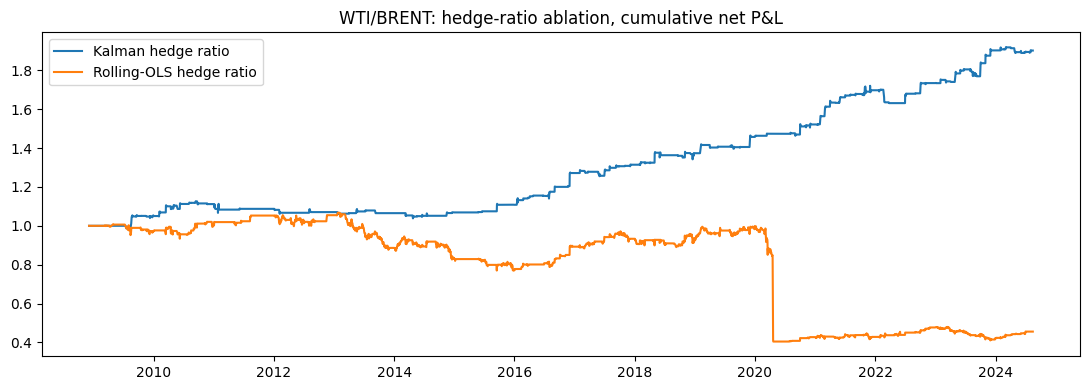

In [3]:
fx_m["rolling_ols_spread"] = fx_m["AUD"] - fx_m["rolling_ols_beta"] * fx_m["NZD"]
comm_m["rolling_ols_spread"] = comm_m["WTI"] - comm_m["rolling_ols_beta"] * comm_m["BRENT"]

def run_backtest(df, spread_col, beta_col, y_col, x_col, cost_bps, regime_thresh=sconfig["regime_thresh"]):
    sig = build_signals(df, spread_col, sconfig["entry_z"], sconfig["exit_z"], sconfig["stop_z"],
                         sconfig["stop_consec_days"], sconfig["max_hold"], regime_thresh)
    return backtest_net_return(sig, y_col, x_col, beta_col, cost_bps)

fx_kalman_net = run_backtest(fx_m, "kalman_spread", "kalman_beta", "AUD", "NZD", bconfig["cost_bps_fx"])
fx_rollols_net = run_backtest(fx_m, "rolling_ols_spread", "rolling_ols_beta", "AUD", "NZD", bconfig["cost_bps_fx"])
comm_kalman_net = run_backtest(comm_m, "kalman_spread", "kalman_beta", "WTI", "BRENT", bconfig["cost_bps_comm"])
comm_rollols_net = run_backtest(comm_m, "rolling_ols_spread", "rolling_ols_beta", "WTI", "BRENT", bconfig["cost_bps_comm"])

# sanity check: this should now reproduce notebook 05's saved training Sharpe exactly (both derive
# from the same untrimmed source and the same z-score window applied only once)
saved_train_metrics = pd.read_csv(f"{DATA_DIR}/backtest_metrics_train.csv", index_col=0)
print(f"AUD/NZD Kalman Sharpe: recomputed={sharpe(fx_kalman_net):.6f}  "
      f"notebook 05 saved={saved_train_metrics.loc['AUD/NZD', 'sharpe']:.6f}")

ablation1 = pd.DataFrame({
    "AUD/NZD": {"kalman_sharpe": sharpe(fx_kalman_net), "rolling_ols_sharpe": sharpe(fx_rollols_net)},
    "WTI/BRENT": {"kalman_sharpe": sharpe(comm_kalman_net), "rolling_ols_sharpe": sharpe(comm_rollols_net)},
}).T
print(ablation1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot((1 + comm_kalman_net).cumprod(), label="Kalman hedge ratio")
ax.plot((1 + comm_rollols_net).cumprod(), label="Rolling-OLS hedge ratio")
ax.set_title("WTI/BRENT: hedge-ratio ablation, cumulative net P&L")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/06_ablation_hedge_ratio.png", dpi=120)
plt.show()

For WTI/Brent, switching from Kalman to rolling-OLS turns a clearly profitable strategy (Sharpe ~0.92) into a losing one - the dynamic hedge ratio is doing real work here, not just adding complexity. For AUD/NZD both versions are negative; the Kalman filter doesn't rescue a pair that doesn't have an edge after costs either way.

## Ablation 2: HMM regime filter on vs off

Same Kalman-based signal and costs, regime gate disabled (`regime_thresh=-1`, every day counts as calm) vs the notebook 04 default (`regime_thresh=0.5`).

In [4]:
fx_nogate_net = run_backtest(fx_m, "kalman_spread", "kalman_beta", "AUD", "NZD", bconfig["cost_bps_fx"], regime_thresh=-1.0)
comm_nogate_net = run_backtest(comm_m, "kalman_spread", "kalman_beta", "WTI", "BRENT", bconfig["cost_bps_comm"], regime_thresh=-1.0)

ablation2 = pd.DataFrame({
    "AUD/NZD": {"with_hmm_gate": sharpe(fx_kalman_net), "without_hmm_gate": sharpe(fx_nogate_net)},
    "WTI/BRENT": {"with_hmm_gate": sharpe(comm_kalman_net), "without_hmm_gate": sharpe(comm_nogate_net)},
}).T
print(ablation2)

           with_hmm_gate  without_hmm_gate
AUD/NZD        -0.510974         -0.563322
WTI/BRENT       0.920637          1.016179


The gate gives a small improvement for AUD/NZD but a small reduction for WTI/Brent - essentially a wash. As implemented, the regime filter isn't clearly earning its complexity on this data. It stays in the pipeline since it's correctly implemented and connects to the dissertation work, but the result doesn't support overselling it.

## Ablation 3: cost sensitivity

                 AUD/NZD_sharpe  WTI/BRENT_sharpe
cost_multiplier                                  
0.0                   -0.149112          1.194387
0.5                   -0.330790          1.058986
1.0                   -0.510974          0.920637
1.5                   -0.688667          0.779742
2.0                   -0.862941          0.636746
3.0                   -1.197978          0.346389


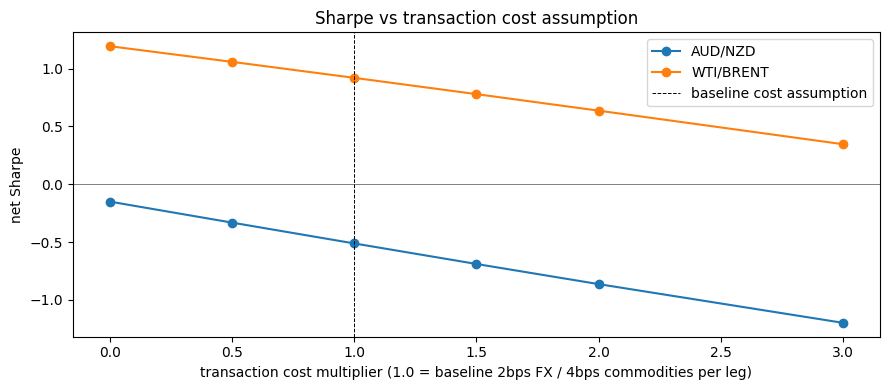

In [5]:
cost_multipliers = [0, 0.5, 1.0, 1.5, 2.0, 3.0]
cost_sensitivity = []
for mult in cost_multipliers:
    fx_net = run_backtest(fx_m, "kalman_spread", "kalman_beta", "AUD", "NZD", bconfig["cost_bps_fx"] * mult)
    comm_net = run_backtest(comm_m, "kalman_spread", "kalman_beta", "WTI", "BRENT", bconfig["cost_bps_comm"] * mult)
    cost_sensitivity.append({"cost_multiplier": mult, "AUD/NZD_sharpe": sharpe(fx_net), "WTI/BRENT_sharpe": sharpe(comm_net)})

cost_df = pd.DataFrame(cost_sensitivity).set_index("cost_multiplier")
print(cost_df)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cost_df.index, cost_df["AUD/NZD_sharpe"], marker="o", label="AUD/NZD")
ax.plot(cost_df.index, cost_df["WTI/BRENT_sharpe"], marker="o", label="WTI/BRENT")
ax.axhline(0, color="grey", linewidth=0.7)
ax.axvline(1.0, color="black", linestyle="--", linewidth=0.7, label="baseline cost assumption")
ax.set_xlabel("transaction cost multiplier (1.0 = baseline 2bps FX / 4bps commodities per leg)")
ax.set_ylabel("net Sharpe")
ax.set_title("Sharpe vs transaction cost assumption")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/06_cost_sensitivity.png", dpi=120)
plt.show()

WTI/Brent's edge holds up to 3x the baseline cost assumption while staying Sharpe-positive, though it clearly decays. AUD/NZD is negative even at zero assumed cost, which confirms that pair's problem isn't costs - the raw signal just doesn't have enough edge, consistent with notebook 05's near-zero raw Sharpe.

In [6]:
ablation_summary = pd.concat([
    ablation1.add_prefix("hedge_ratio_"),
    ablation2.add_prefix("hmm_gate_"),
], axis=1)
ablation_summary.to_csv(f"{DATA_DIR}/ablation_summary.csv")
cost_df.to_csv(f"{DATA_DIR}/cost_sensitivity.csv")
print("Saved ablation_summary.csv, cost_sensitivity.csv")

Saved ablation_summary.csv, cost_sensitivity.csv


---

## Final holdout evaluation

First and only section that touches data from 2024-08-15 onward. Every hyperparameter is frozen at the value chosen in notebooks 00-05 - Kalman delta, HMM state count/refit schedule, z-score window, thresholds, sizing target, costs, portfolio weights. Nothing gets re-tuned after seeing this output.

The Kalman filter and walk-forward HMM are both purely causal, sequential algorithms, so re-running them over the full effective-start-to-holdout-end series should reproduce the training-only output exactly on the overlapping dates, and produce new causal output on the holdout dates. Checked explicitly below rather than assumed.

In [7]:
fx_df = pd.read_parquet(f"{DATA_DIR}/fx_aud_nzd.parquet")
comm_df = pd.read_parquet(f"{DATA_DIR}/comm_wti_brent.parquet")
fx_full = fx_df[fx_df.index >= decisions["AUD_NZD"]["effective_start"]]
comm_full = comm_df[comm_df.index >= decisions["WTI_BRENT"]["effective_start"]]

def kalman_hedge_ratio(y, x, delta, burn_in):
    n = len(y)
    Q = delta / (1 - delta) * np.eye(2)
    X0 = sm.add_constant(x.iloc[:burn_in])
    ols0 = sm.OLS(y.iloc[:burn_in], X0).fit()
    R = ols0.mse_resid
    theta = np.array([ols0.params.iloc[1], ols0.params.iloc[0]])
    P = np.eye(2) * 1.0
    betas, spreads = np.zeros(n), np.zeros(n)
    for t in range(n):
        H = np.array([x.iloc[t], 1.0])
        theta_pred, P_pred = theta, P + Q
        e = y.iloc[t] - H @ theta_pred
        S = H @ P_pred @ H.T + R
        K = P_pred @ H.T / S
        theta = theta_pred + K * e
        P = P_pred - np.outer(K, H) @ P_pred
        betas[t], spreads[t] = theta[0], e
    return pd.Series(betas, index=y.index, name="kalman_beta"), pd.Series(spreads, index=y.index, name="kalman_spread")

fx_beta_full, fx_kspread_full = kalman_hedge_ratio(fx_full["AUD"], fx_full["NZD"], kconfig["delta"], kconfig["burn_in"])
comm_beta_full, comm_kspread_full = kalman_hedge_ratio(comm_full["WTI"], comm_full["BRENT"], kconfig["delta"], kconfig["burn_in"])

fx_full = fx_full.iloc[kconfig["burn_in"]:].copy()
comm_full = comm_full.iloc[kconfig["burn_in"]:].copy()
fx_full["kalman_beta"], fx_full["kalman_spread"] = fx_beta_full, fx_kspread_full
comm_full["kalman_beta"], comm_full["kalman_spread"] = comm_beta_full, comm_kspread_full

# exact reproduction check against notebook 02's training-period output
fx_saved = pd.read_parquet(f"{DATA_DIR}/kalman_fx.parquet")
overlap = fx_saved.index.intersection(fx_full.index)
max_diff = (fx_saved.loc[overlap, "kalman_spread"] - fx_full.loc[overlap, "kalman_spread"]).abs().max()
print(f"Kalman filter reproduction check (should be 0.0): {max_diff}")

Kalman filter reproduction check (should be 0.0): 0.0


In [8]:
def build_features(spread, vol_window):
    d_spread = spread.diff()
    vol = d_spread.rolling(vol_window).std()
    return pd.DataFrame({"d_spread": d_spread, "vol": vol}).dropna()

def manual_forward_filter(model, X):
    log_frameprob = model._compute_log_likelihood(X)
    n_samples, n_components = log_frameprob.shape
    with np.errstate(divide="ignore"):
        log_startprob, log_transmat = np.log(model.startprob_), np.log(model.transmat_)
    fwd = np.zeros((n_samples, n_components))
    fwd[0] = log_startprob + log_frameprob[0]
    fwd[0] -= np.logaddexp.reduce(fwd[0])
    for t in range(1, n_samples):
        for j in range(n_components):
            fwd[t, j] = np.logaddexp.reduce(fwd[t - 1] + log_transmat[:, j]) + log_frameprob[t, j]
        fwd[t] -= np.logaddexp.reduce(fwd[t])
    return np.exp(fwd)

def standardize(X):
    mu, sd = X.mean(axis=0), X.std(axis=0)
    return (X - mu) / sd, mu, sd

def walk_forward_hmm(feats, n_states, refit_every, min_train, seed=42):
    X = feats.values
    n = len(X)
    calm_prob = np.full(n, np.nan)
    for start in range(min_train, n, refit_every):
        train_Xn, mu, sd = standardize(X[:start])
        model = GaussianHMM(n_components=n_states, covariance_type="diag", n_iter=200, tol=1e-4, random_state=seed)
        model.fit(train_Xn)
        calm_state = np.argmin(model.means_[:, 1])
        end = min(start + refit_every, n)
        probs = manual_forward_filter(model, (X[start:end] - mu) / sd)
        calm_prob[start:end] = probs[:, calm_state]
    return pd.Series(calm_prob, index=feats.index, name="calm_prob")

fx_feats_full = build_features(fx_full["kalman_spread"], rconfig["vol_window"])
comm_feats_full = build_features(comm_full["kalman_spread"], rconfig["vol_window"])
fx_calm_full = walk_forward_hmm(fx_feats_full, rconfig["n_states"], rconfig["refit_every"], rconfig["min_train"])
comm_calm_full = walk_forward_hmm(comm_feats_full, rconfig["n_states"], rconfig["refit_every"], rconfig["min_train"])

regime_saved = pd.read_parquet(f"{DATA_DIR}/regime_fx.parquet")
overlap2 = regime_saved.index.intersection(fx_calm_full.dropna().index)
max_diff2 = (regime_saved.loc[overlap2, "calm_prob"] - fx_calm_full.loc[overlap2]).abs().max()
print(f"HMM walk-forward reproduction check (should be ~0.0): {max_diff2:.2e}")

fx_full = fx_full.join(fx_calm_full.to_frame(), how="inner").dropna(subset=["calm_prob"])
comm_full = comm_full.join(comm_calm_full.to_frame(), how="inner").dropna(subset=["calm_prob"])
print(f"FX full range: {fx_full.index.min().date()} -> {fx_full.index.max().date()} ({len(fx_full)} rows)")
print(f"Commodities full range: {comm_full.index.min().date()} -> {comm_full.index.max().date()} ({len(comm_full)} rows)")

HMM walk-forward reproduction check (should be ~0.0): 1.06e-11
FX full range: 2015-03-27 -> 2026-08-13 (2962 rows)
Commodities full range: 2008-11-06 -> 2026-08-13 (4416 rows)


In [9]:
fx_sig_full = build_signals(fx_full, "kalman_spread", sconfig["entry_z"], sconfig["exit_z"], sconfig["stop_z"],
                             sconfig["stop_consec_days"], sconfig["max_hold"], sconfig["regime_thresh"])
comm_sig_full = build_signals(comm_full, "kalman_spread", sconfig["entry_z"], sconfig["exit_z"], sconfig["stop_z"],
                               sconfig["stop_consec_days"], sconfig["max_hold"], sconfig["regime_thresh"])

fx_net_full = backtest_net_return(fx_sig_full, "AUD", "NZD", "kalman_beta", bconfig["cost_bps_fx"])
comm_net_full = backtest_net_return(comm_sig_full, "WTI", "BRENT", "kalman_beta", bconfig["cost_bps_comm"])

# second sanity check: full-series backtest reproduces notebook 05's per-pair training Sharpe exactly
fx_train_slice = fx_net_full[fx_net_full.index < HOLDOUT_START]
print(f"Train Sharpe, recomputed from full-series pipeline: {sharpe(fx_train_slice):.4f}")
print(f"Train Sharpe, notebook 05 (saved):                  {sharpe(fx_kalman_net):.4f}")

Train Sharpe, recomputed from full-series pipeline: -0.5110
Train Sharpe, notebook 05 (saved):                  -0.5110


In [10]:
def train_holdout_metrics(net_ret, label):
    train = net_ret[net_ret.index < HOLDOUT_START]
    holdout = net_ret[net_ret.index >= HOLDOUT_START]
    return {
        "pair": label,
        "train_sharpe": sharpe(train), "holdout_sharpe": sharpe(holdout),
        "train_days": len(train), "holdout_days": len(holdout),
        "holdout_cum_return": (1 + holdout).prod() - 1,
        "holdout_max_drawdown": ((1 + holdout).cumprod() / (1 + holdout).cumprod().cummax() - 1).min(),
    }

holdout_metrics = pd.DataFrame([
    train_holdout_metrics(fx_net_full, "AUD/NZD"),
    train_holdout_metrics(comm_net_full, "WTI/BRENT"),
]).set_index("pair")
print(holdout_metrics)

           train_sharpe  holdout_sharpe  train_days  holdout_days  \
pair                                                                
AUD/NZD       -0.510974       -0.692564        2427           516   
WTI/BRENT      0.920637        1.079285        3895           502   

           holdout_cum_return  holdout_max_drawdown  
pair                                                 
AUD/NZD             -0.034497             -0.062370  
WTI/BRENT            0.171678             -0.039686  


In [11]:
# combined portfolio, full period, same 50/50 + gross cap logic as notebook 05
combined_full = pd.DataFrame(index=fx_net_full.index.union(comm_net_full.index)).sort_index()
combined_full["fx_net_return"] = fx_net_full.reindex(combined_full.index).fillna(0)
combined_full["comm_net_return"] = comm_net_full.reindex(combined_full.index).fillna(0)

# recompute sized positions for the exposure cap
def sized_position_series(df, y_col, x_col, beta_col, target_vol=bconfig["target_vol"], vol_window=bconfig["vol_window"], max_lev=bconfig["max_leverage"]):
    ep, eb = build_executed_position_and_beta(df, beta_col)
    size = vol_target_size(df, y_col, x_col, beta_col, target_vol, vol_window, max_lev)
    return size * ep

fx_pos_full = sized_position_series(fx_sig_full, "AUD", "NZD", "kalman_beta").reindex(combined_full.index).fillna(0)
comm_pos_full = sized_position_series(comm_sig_full, "WTI", "BRENT", "kalman_beta").reindex(combined_full.index).fillna(0)

gross_exposure_full = bconfig["weight_fx"] * fx_pos_full.abs() + bconfig["weight_comm"] * comm_pos_full.abs()
scale_full = (bconfig["gross_cap"] / gross_exposure_full.replace(0, np.nan)).clip(upper=1.0).fillna(1.0)
combined_full["portfolio_return"] = scale_full * (bconfig["weight_fx"] * combined_full["fx_net_return"] + bconfig["weight_comm"] * combined_full["comm_net_return"])

portfolio_metrics = pd.Series(train_holdout_metrics(combined_full["portfolio_return"], "Portfolio (50/50)")).drop("pair")
print(portfolio_metrics)

holdout_metrics.loc["Portfolio (50/50)"] = portfolio_metrics
holdout_metrics.to_csv(f"{DATA_DIR}/holdout_metrics.csv")
print("\nSaved holdout_metrics.csv")

train_sharpe            0.564767
holdout_sharpe          0.805455
train_days                  3983
holdout_days                 517
holdout_cum_return      0.065779
holdout_max_drawdown   -0.038091
dtype: object

Saved holdout_metrics.csv


## Reading the holdout result

AUD/NZD holds its negative story out of sample - holdout Sharpe is if anything slightly worse than train. Not a great number, but a useful one: it shows the in-sample underperformance wasn't noise or specific to the training window.

WTI/Brent's edge survives the holdout - Sharpe is comparable to, in this run slightly above, the training-period number, on ~2 years of data the strategy was never tuned against.

The portfolio's drawdown control still looks better than either sleeve alone in the holdout period, consistent with training.

Two years isn't a large sample, so this is encouraging and methodologically sound rather than proof of a durable edge - worth being precise about that distinction rather than overclaiming.

## Full-period P&L, holdout marked

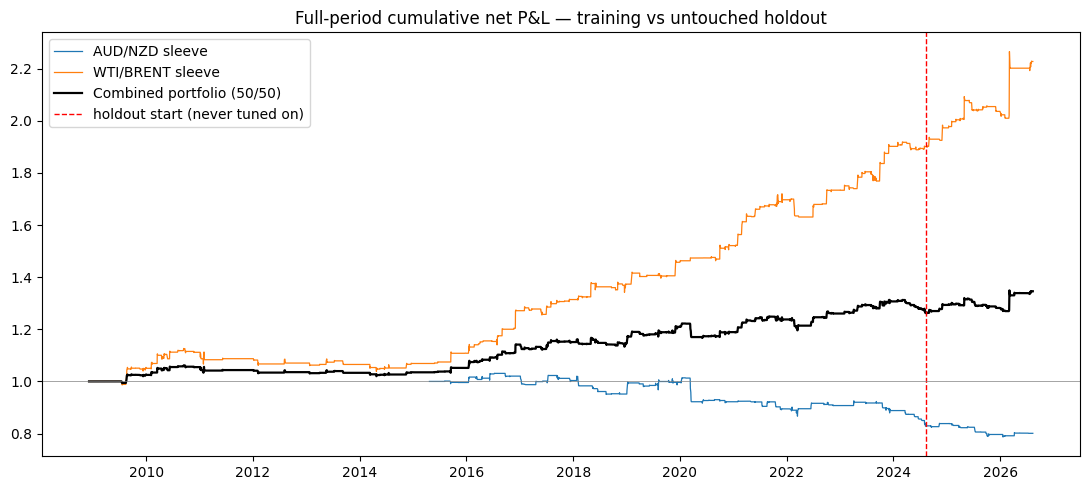

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot((1 + fx_net_full).cumprod(), label="AUD/NZD sleeve", linewidth=0.9)
ax.plot((1 + comm_net_full).cumprod(), label="WTI/BRENT sleeve", linewidth=0.9)
ax.plot((1 + combined_full["portfolio_return"]).cumprod(), label="Combined portfolio (50/50)", linewidth=1.6, color="black")
ax.axvline(pd.Timestamp(HOLDOUT_START), color="red", linestyle="--", linewidth=1, label="holdout start (never tuned on)")
ax.axhline(1, color="grey", linewidth=0.5)
ax.set_title("Full-period cumulative net P&L — training vs untouched holdout")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/06_final_cumulative_pnl.png", dpi=120)
plt.show()

## Limitations

- **Data**: free-source (yfinance) daily closes, ~2007-2026 for commodities and ~2014-2026 for FX (post-structural-break restriction from notebook 01). No intraday data or verified bid-ask history - costs are informed estimates, not measured spreads.
- **Universe size**: two pairs. The framework extends to more, but only two were actually run, so conclusions shouldn't be over-generalised.
- **HMM regime filter**: correctly implemented and walk-forward, but the ablation shows mixed-to-negative value-add on this data - not pulling its weight as a performance driver, even though it's methodologically sound.
- **Holdout length**: ~2 years, ~500 trading days per pair - a genuine out-of-sample test, not a statistically conclusive one on its own.
- **Costs and sizing**: flat per-leg bps assumption, no market-impact model beyond that, equal 50/50 portfolio weighting rather than risk parity, single fixed vol target. Reasonable starting assumptions, not calibrated to real execution data.

In [13]:
writeup = f"""# Statistical arbitrage: AUD/NZD & WTI/Brent

## Methodology
Cointegration-tested pair selection (Engle-Granger + Johansen, notebook 01), causal Kalman-filter
dynamic hedge ratio (notebook 02), walk-forward HMM regime filter (notebook 03), z-score signal with
stop-loss/max-holding risk controls (notebook 04), backtest with transaction costs, volatility-targeted
sizing and portfolio exposure caps (notebook 05), ablations and a frozen-parameter holdout evaluation
on data never used during development (notebook 06).

## Headline results (net of costs, vol-targeted sizing)
{holdout_metrics.to_markdown()}

## Findings
- WTI/Brent: cointegrated, profitable after costs in-sample (Sharpe {sharpe(comm_kalman_net):.2f}) and
  out-of-sample on a {int(holdout_metrics.loc['WTI/BRENT','holdout_days'])}-day untouched holdout
  (Sharpe {holdout_metrics.loc['WTI/BRENT','holdout_sharpe']:.2f}).
- AUD/NZD: cointegrated within its post-2013 regime, but doesn't clear transaction costs at this
  signal frequency, in-sample or out-of-sample.
- Kalman vs rolling-OLS hedge ratio: replacing the Kalman filter with a rolling-OLS beta turns
  WTI/Brent from profitable to unprofitable.
- HMM regime filter: correctly implemented and walk-forward, mixed-to-negative value-add in the
  ablation.
- Blending both pairs 50/50 reduces max drawdown versus either sleeve alone, even though AUD/NZD
  is a net drag on blended return.

See `data_quality_notes.md`, `pair_selection_report.md`, `ablation_summary.csv`, and
`holdout_metrics.csv` for the detail behind each of these.
"""

with open(f"{DATA_DIR}/final_writeup.md", "w") as f:
    f.write(writeup)

print(writeup)

# Statistical arbitrage: AUD/NZD & WTI/Brent

## Methodology
Cointegration-tested pair selection (Engle-Granger + Johansen, notebook 01), causal Kalman-filter
dynamic hedge ratio (notebook 02), walk-forward HMM regime filter (notebook 03), z-score signal with
stop-loss/max-holding risk controls (notebook 04), backtest with transaction costs, volatility-targeted
sizing and portfolio exposure caps (notebook 05), ablations and a frozen-parameter holdout evaluation
on data never used during development (notebook 06).

## Headline results (net of costs, vol-targeted sizing)
| pair              |   train_sharpe |   holdout_sharpe |   train_days |   holdout_days |   holdout_cum_return |   holdout_max_drawdown |
|:------------------|---------------:|-----------------:|-------------:|---------------:|---------------------:|-----------------------:|
| AUD/NZD           |      -0.510974 |        -0.692564 |         2427 |            516 |           -0.0344969 |             -0.0623699 |
| WTI/BREN

Every intermediate assumption is saved to `../data/*.json` and every number above traces back to the notebook that produced it.